# NIM : 11322004
# Nama : Destina Manurung
# Prodi : D3 Teknologi Informasi 2022

## a. Klasifikasi menggunakan K-NN dan Naïve Bayes

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from pandas.plotting import parallel_coordinates

# Load dataset Iris dari scikit-learn
iris = load_iris()

In [24]:
# Konversi data menjadi DataFrame Pandas
df = pd.DataFrame(iris.data, columns=iris.feature_names) 
df["Species"] = iris.target_names[iris.target]

# Definisikan X (fitur) dan y (target/label)
X = df.drop(columns=["Species"]) 
y = df["Species"]

print(X)


     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  5.1               3.5                1.4               0.2
1                  4.9               3.0                1.4               0.2
2                  4.7               3.2                1.3               0.2
3                  4.6               3.1                1.5               0.2
4                  5.0               3.6                1.4               0.2
..                 ...               ...                ...               ...
145                6.7               3.0                5.2               2.3
146                6.3               2.5                5.0               1.9
147                6.5               3.0                5.2               2.0
148                6.2               3.4                5.4               2.3
149                5.9               3.0                5.1               1.8

[150 rows x 4 columns]


In [25]:
y

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: Species, Length: 150, dtype: object

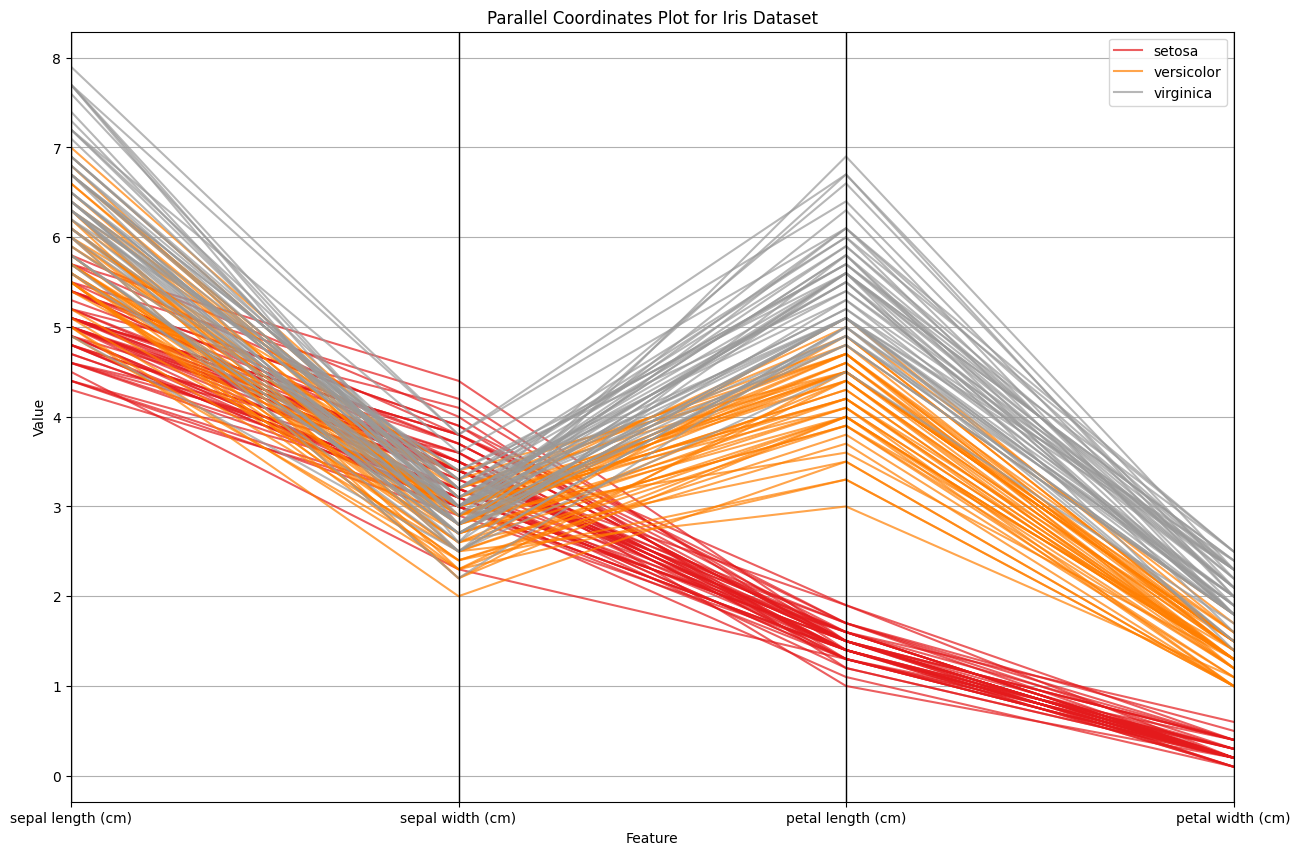

In [26]:
# Plot Parallel Coordinates
plt.figure(figsize=(15, 10)) 
parallel_coordinates(df, class_column="Species", colormap=plt.cm.Set1, alpha=0.7 )
plt.title("Parallel Coordinates Plot for Iris Dataset")
plt.xlabel("Feature") 
plt.ylabel("Value") 
plt.grid(True)
plt.show()


In [27]:
from sklearn.preprocessing import LabelEncoder 
lab = LabelEncoder()
y = lab.fit_transform(y) 
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(X, test_size=0.2, random_state=0) 
y_train, y_test = train_test_split(y, test_size=0.2, random_state=0)

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# k = 3
knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean') 
knn.fit(X_train, y_train)

KNeighborsClassifier(metric='euclidean', n_neighbors=3)

In [30]:
y_pred = knn.predict(X_test) 
y_pred

array([2, 1, 0, 2, 0, 2, 0, 1, 1, 1, 2, 1, 1, 1, 2, 0, 1, 1, 0, 0, 2, 1,
       0, 0, 2, 0, 0, 1, 1, 0])

In [31]:
result = accuracy_score(y_test, y_pred) 
result

0.9666666666666667

In [32]:
# Import dataset 

df = pd.read_csv("breast-cancer.csv")
print (df)

           id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0      842302         M        17.99         10.38          122.80     1001.0   
1      842517         M        20.57         17.77          132.90     1326.0   
2    84300903         M        19.69         21.25          130.00     1203.0   
3    84348301         M        11.42         20.38           77.58      386.1   
4    84358402         M        20.29         14.34          135.10     1297.0   
..        ...       ...          ...           ...             ...        ...   
564    926424         M        21.56         22.39          142.00     1479.0   
565    926682         M        20.13         28.25          131.20     1261.0   
566    926954         M        16.60         28.08          108.30      858.1   
567    927241         M        20.60         29.33          140.10     1265.0   
568     92751         B         7.76         24.54           47.92      181.0   

     smoothness_mean  compa

In [7]:
feature_columns = ['radius_mean', 'texture_mean']
X = df[feature_columns].values
y = df['perimeter_mean'].values

In [8]:
X

array([[17.99, 10.38],
       [20.57, 17.77],
       [19.69, 21.25],
       ...,
       [16.6 , 28.08],
       [20.6 , 29.33],
       [ 7.76, 24.54]], shape=(569, 2))

In [9]:
y

array([122.8 , 132.9 , 130.  ,  77.58, 135.1 ,  82.57, 119.6 ,  90.2 ,
        87.5 ,  83.97, 102.7 , 103.6 , 132.4 , 103.7 ,  93.6 ,  96.73,
        94.74, 108.1 , 130.  ,  87.46,  85.63,  60.34, 102.5 , 137.2 ,
       110.  , 116.  ,  97.41, 122.1 , 102.4 , 115.  , 124.8 ,  77.93,
       112.8 , 127.9 , 107.  , 110.1 ,  93.63,  82.61,  95.54,  88.4 ,
        86.18,  71.9 , 128.3 ,  87.32,  85.42, 123.7 ,  51.71,  85.98,
        78.04,  86.91,  74.72,  87.21,  75.71, 120.3 ,  97.26,  73.34,
       125.5 ,  95.55,  82.61,  54.34,  64.55,  54.66,  96.42,  59.2 ,
        82.69,  97.4 ,  60.11,  71.8 ,  58.79,  81.37, 123.6 ,  58.79,
       114.2 ,  90.43,  79.19, 104.1 ,  87.91, 120.2 , 143.7 ,  83.19,
        73.81,  86.49, 171.5 , 129.1 ,  76.95, 121.1 ,  94.25, 122.  ,
        79.78,  95.77,  94.57, 100.2 ,  84.74,  86.6 , 100.3 , 132.4 ,
        77.79,  62.11,  74.34,  94.48,  88.05,  43.79,  77.22,  63.95,
        67.41,  87.21,  75.17,  79.01, 152.8 ,  72.48,  62.5 ,  82.15,
      

In [33]:
#encde data y menjadi numerik

en = LabelEncoder()
y = en.fit_transform(y) 
y


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

['g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g'
 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g' 'g

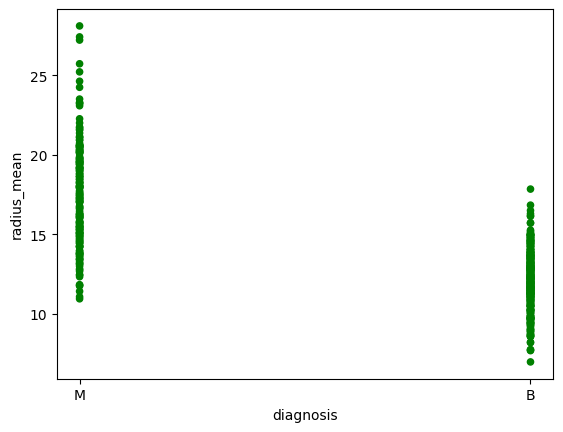

In [13]:
from numpy import where 
df['key1'] = (y)
colors = np.where(df["key1"]==0,'r','g') 
print(colors)
df.plot.scatter(x=1,y=2,c=colors) 
plt.show()

In [34]:
# split train test
X_train, X_test = train_test_split(X, test_size=0.2, random_state=0) 
y_train, y_test = train_test_split(y, test_size=0.2, random_state=0)

In [35]:
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean') 
knn.fit(X_train, y_train)

KNeighborsClassifier(metric='euclidean')

In [36]:
y_pred = knn.predict(X_test) 
y_pred

array([2, 1, 0, 2, 0, 2, 0, 1, 1, 1, 2, 1, 1, 1, 2, 0, 1, 1, 0, 0, 2, 1,
       0, 0, 2, 0, 0, 1, 1, 0])

In [37]:
result = accuracy_score(y_test, y_pred) 
result

0.9666666666666667

In [ ]:
#untuk menemukan nilai K yang tepat, bisa dengan mencoba beberapa variasi nilai

array_k = []
for i in range(1,11):
    knn = KNeighborsClassifier(n_neighbors=i, metric='euclidean') 
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    # Calculate accuracy
    result = accuracy_score(y_test, y_pred)

    # Store the accuracy result
    array_k.append(result)

plt.plot(array_k)
plt.ylabel('Nilai Akurasi') 
plt.xlabel('Nilai K')
plt.xticks(np.arange(10),('1','2','3','4','5','6','7','8','9','10'))
plt.show()